In [2]:
import os
from tqdm import tqdm
import pandas as pd
import numpy as np
from pathlib import Path
from glob import glob

# TODO: Fix ProteoBench dependency
from SCI_py.data.parse import df_to_anndata, align_obs_across_anndata
from SCI_py.data.read import load_spectronaut

tqdm.pandas()

In [3]:
condition_setup_wyss = pd.read_csv(
    '/public/conode53/sam/SCI/Bogdan/spectronaut/human/directdia/20260427_233110_Bogdan_04272026/Bogdan_04272026_ConditionSetup.tsv',
    sep='\t'
)
condition_setup_wyss['Condition'] = condition_setup_wyss.apply(
    lambda x: x['#'],
    axis=1
)
condition_setup_wyss['Replicate'] = 1

condition_setup_wyss.to_csv(
    '/public/conode53/sam/SCI/Bogdan/spectronaut/human/conditions.tsv',
    sep='\t',
    index=False
)

There was some discussion about the search strategy of Spectronaut.

The strategy is as follows:
Each plate was searched independently with the DirectDIA+ approach and afterwards all SNE result files were combined naively with the SNE combine method. However, since it is believed different search spaces are created within each plate, combining them as such will result in inaccurate FDR calculations (and quantifications?).

Therefore, it was suggested to use the data from the separate searches and make them comparable by only using proteotypic peptides and perform the protein inference/quantification externally ourselves.

Here, the impact of the SNE combine on the 9 SNE files is investigated and quantified

In [104]:
ROOT = '/public/conode53/sam/SCI'

reports = {
    name: load_spectronaut(
        glob(
            os.path.join(
                ROOT,
                name,
                'spectronaut',
                'human',
                'directdia',
                '*',
                '*Report (Normal).tsv'
            )
        )[0] 
    )
    for name in [
        'Bogdan',
        'Claudia',
        'Erwin',
        'Jeewan',
        'Karl_plate_5',
        'Kelly',
        'KI_Akos',
        'KI_Akos_11'
    ]
}

100%|██████████| 2605858/2605858 [00:15<00:00, 168481.02it/s]


In [105]:
NOTEBOOK_DIR = Path().resolve()
ROOT_OUT      = NOTEBOOK_DIR / "../../Data"
ROOT_OUT      = ROOT_OUT.resolve()
ROOT_OUT.mkdir(parents=True, exist_ok=True)

# Allow user override via environment variable
ROOT_OUT = Path(os.environ.get("SCI_DATA_DIR", ROOT_OUT))

ROOT_OUT.mkdir(parents=True, exist_ok=True)
print(f"Output directory: {ROOT_OUT}")

METADATA_PATH = os.path.join(
    ROOT_OUT,
    'metadata',
    'metadata.parquet'
)

metadata = pd.read_parquet(
    METADATA_PATH
)

Output directory: /home/sam/SCI/SCI/Data


In [106]:
reports = {
    k: v.merge(metadata, on=['plate_id', 'sample_name']) for k, v in reports.items()
}

In [107]:
cols_protpept_metadata = [
    'PG.ProteinGroups',
    'PG.ProteinAccessions',
    'PEP.StrippedSequence',
    'PEP.IsProteotypic',
    'EG.ModifiedSequence',
    'FG.Charge',
    'FG.LabeledSequence',
    'FG.PrecursorIon'
]
cols_idconf = [
    'PG.Pvalue',
    'PG.Qvalue',
    'FG.Qvalue',
    'EG.GlobalPrecursorQvalue',
    'PG.Cscore'
]
cols_quant = [
    'PG.Quantity',
    'EG.TargetQuantity (Settings)',
    'EG.ReferenceQuantity (Settings)',
    'EG.TotalQuantity (Settings)',
    'FG.Quantity',
]
cols_peptfeatures = [
    # Retention time
    'EG.ApexRT',
    'EG.RTPredicted',
    'EG.iRTEmpirical',
    'EG.iRTPredicted',
    
    # MS2 features
    'FG.PrecWindowNumber',
    'FG.CScore',
]
cols_metadata = [
    'sample_name',
    'plate_id',
    'plate_idx',
    'source name',
    'comment[X position]',
    'comment[Y position]',
    'comment[Plate Number]',
    'comment[Gradient time]',
    'comment[thawing timepoint]',
    'comment[plate arrival]',
    'injection_order',
    'institute_name',
    'Reinjection',
    'Diameter',
    'Elongation',
    'Circularity',
    'Doublet',
    'Dividing',
    'Dying',
    'CellInBlank',
    'comment[plate arrival]_date',
    'comment[plate arrival]_time', 'comment[plate arrival]_datetime',
    'comment[Gradient time]_date', 'comment[Gradient time]_time',
    'comment[Gradient time]_datetime', 'instrument_type'
]

col_sample_index = ['sample_id']

var_cols = cols_protpept_metadata + cols_idconf + cols_peptfeatures

In [108]:
reports['Bogdan'].columns.tolist()

['E.Errors',
 'E.Warnings',
 'E.LFQMethod',
 'R.Condition',
 'R.Replicate',
 'R.Fraction',
 'R.FileName',
 'R.Label',
 'PG.Pvalue',
 'PG.Qvalue',
 'PG.PEP',
 'PG.Cscore (Run-Wise)',
 'PG.QValue (Run-Wise)',
 'PG.PEP (Run-Wise)',
 'PG.PValue (Run-Wise)',
 'PG.Cscore',
 'PG.RunEvidenceCount',
 'PG.ProteinGroups',
 'PG.GroupLabel',
 'PG.ProteinAccessions',
 'PG.Quantity',
 'PEP.GroupingKey',
 'PEP.GroupingKeyType',
 'PEP.StrippedSequence',
 'PEP.NrOfMissedCleavages',
 'PEP.IsProteotypic',
 'PEP.RunEvidenceCount',
 'PEP.Rank',
 'PEP.UsedForProteinGroupQuantity',
 'PEP.AllOccurringOrganisms',
 'EG.UserGroup',
 'EG.MinProfileQvalue',
 'EG.PercentileQvalue',
 'EG.AvgProfileQvalue',
 'EG.MaxProfileQvalue',
 'EG.GlobalPrecursorQvalue',
 'EG.ModifiedSequence',
 'EG.ModifiedPeptide',
 'EG.IsDecoy',
 'EG.UsedForProteinGroupQuantity',
 'EG.UsedForPeptideQuantity',
 'EG.IntPIMID',
 'EG.Workflow',
 'EG.iRTPredicted',
 'EG.iRTEmpirical',
 'EG.ApexRT',
 'EG.RTPredicted',
 'EG.IsVerified',
 'EG.Cscore',

In [109]:
adata_precursors = {}

for k, report in reports.items():
    report = report.rename(columns={'sample_id_x': 'sample_id'})
    adata_precursors[k], _ = df_to_anndata(
        report,
        feature_col = 'FG.PrecursorIon',
        value_col   = 'EG.TotalQuantity (Settings)',
        sample_col  = 'sample_id',
        obs_cols    = cols_metadata,
        var_cols    = var_cols,
    )
    adata_precursors[k].layers['X_log2'] = np.log2(adata_precursors[k].X)

In [110]:
import anndata
adata_precursor_og = anndata.io.read_h5ad('/home/sam/SCI/SCI/Data/AnnData/base/adata_precursor.h5ad')
adata_precursor_og.obs['n_precursors'] = np.sum(~np.isnan(adata_precursor_og.X), axis=1)

In [111]:
comparisons = {}

for k, adata in adata_precursors.items():
    adata.obs['n_precursors'] = np.sum(~np.isnan(adata.X), axis=1)
    result = pd.merge(adata.obs, adata_precursor_og.obs, on='sample_id')
    comparisons[k] = result

In [112]:
import seaborn as sns
from matplotlib import pyplot as plt
import warnings
from SCI_py.plot.utilities import _save

def plot_precursor_count_diff(
    results:     dict[str, pd.DataFrame],
    col_x:       str        = 'n_precursors_x',
    col_y:       str        = 'n_precursors_y',
    save_dir:    str | None = None,
    filename:    str        = 'precursor_count_diff.png',
    show:        bool       = True,
) -> None:
    """
    Distribution of per-sample precursor count differences across datasets.

    Parameters
    ----------
    results:
        Dict mapping dataset name → DataFrame with ``col_x`` and ``col_y``.
    col_x:
        First precursor count column.
    col_y:
        Second precursor count column (subtracted from col_x).
    save_dir:
        Directory to save figures. ``None`` disables saving.
    filename:
        Output filename.
    show:
        Whether to call ``plt.show()``.
    """
    fig, ax = plt.subplots(figsize=(8, 4))

    for name, df in results.items():
        diff = df[col_x] - df[col_y]
        sns.kdeplot(
            diff,
            ax        = ax,
            label     = name,
            linewidth = 1.5,
            fill      = True,
            alpha     = 0.15,
        )

    ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set(
        xlabel = f'{col_x} − {col_y}',
        ylabel = 'Density',
        title  = 'Precursor count difference',
    )
    ax.legend(frameon=False, fontsize=8, bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.spines[['top', 'right']].set_visible(False)

    with warnings.catch_warnings():
        warnings.simplefilter('ignore', UserWarning)
        fig.tight_layout()

    if save_dir:
        _save(fig, os.path.join(save_dir, filename))

    plt.show() if show else plt.close(fig)
    
def plot_precursor_overlap(
    adata_a:     "anndata.AnnData",
    adata_b:     "anndata.AnnData",
    label_a:     str        = 'A',
    label_b:     str        = 'B',
    save_dir:    str | None = None,
    filename:    str        = 'precursor_overlap.png',
    show:        bool       = True,
) -> pd.DataFrame:
    """
    Per-sample overlap of identified precursors between two AnnData objects.

    Parameters
    ----------
    adata_a / adata_b:
        AnnData objects sharing obs and var indices.
    label_a / label_b:
        Display labels for each object.
    save_dir:
        Directory to save figures.
    filename:
        Output filename.
    show:
        Whether to call ``plt.show()``.

    Returns
    -------
    pd.DataFrame
        Per-sample overlap statistics.
    """
    import scipy.sparse as sp

    # align to common samples and features
    common_obs = adata_a.obs_names.intersection(adata_b.obs_names)
    common_var = adata_a.var_names.intersection(adata_b.var_names)

    a = adata_a[common_obs, common_var]
    b = adata_b[common_obs, common_var]

    X_a = a.X.toarray() if sp.issparse(a.X) else np.array(a.X)
    X_b = b.X.toarray() if sp.issparse(b.X) else np.array(b.X)

    X_a = X_a.astype(float)
    X_b = X_b.astype(float)
    X_a[X_a == 0] = np.nan
    X_b[X_b == 0] = np.nan

    id_a    = np.isfinite(X_a)
    id_b    = np.isfinite(X_b)

    n_a     = id_a.sum(axis=1)
    n_b     = id_b.sum(axis=1)
    n_both  = (id_a & id_b).sum(axis=1)
    n_union = (id_a | id_b).sum(axis=1)
    n_only_a = (id_a & ~id_b).sum(axis=1)
    n_only_b = (~id_a & id_b).sum(axis=1)

    stats = pd.DataFrame({
        'sample':      common_obs,
        f'n_{label_a}':     n_a,
        f'n_{label_b}':     n_b,
        'n_overlap':   n_both,
        'n_union':     n_union,
        f'n_only_{label_a}': n_only_a,
        f'n_only_{label_b}': n_only_b,
        'pct_overlap': 100 * n_both / n_union.clip(1),
        'jaccard':     n_both / n_union.clip(1),
    })

    # ── figure ────────────────────────────────────────────────────────────────
    fig, axes = plt.subplots(1, 3, figsize=(14, 4), constrained_layout=True)

    # 1. stacked bar — absolute counts per sample, sorted by overlap
    stats_sorted = stats.sort_values('n_overlap', ascending=False).reset_index(drop=True)

    axes[0].bar(range(len(stats_sorted)), stats_sorted['n_overlap'],
                color='#4393c3', label='Overlap')
    axes[0].bar(range(len(stats_sorted)), stats_sorted[f'n_only_{label_a}'],
                bottom=stats_sorted['n_overlap'],
                color='#f4a582', label=f'Only {label_a}')
    axes[0].bar(range(len(stats_sorted)), stats_sorted[f'n_only_{label_b}'],
                bottom=stats_sorted['n_overlap'] + stats_sorted[f'n_only_{label_a}'],
                color='#92c5de', label=f'Only {label_b}')
    axes[0].set(xlabel='Sample (sorted by overlap)', ylabel='Precursor count',
                title='Absolute overlap per sample')
    axes[0].legend(frameon=False, fontsize=8)
    axes[0].spines[['top', 'right']].set_visible(False)

    # 2. % overlap distribution
    sns.histplot(stats['pct_overlap'], ax=axes[1], bins=30,
                 color='#4393c3', edgecolor='white')
    axes[1].axvline(stats['pct_overlap'].median(), color='black',
                    linewidth=1, linestyle='--',
                    label=f'median = {stats["pct_overlap"].median():.1f}%')
    axes[1].set(xlabel='% overlap (of union)', ylabel='Samples',
                title='Distribution of overlap %')
    axes[1].legend(frameon=False, fontsize=8)
    axes[1].spines[['top', 'right']].set_visible(False)

    # 3. scatter n_a vs n_b colored by overlap %
    sc = axes[2].scatter(
        stats[f'n_{label_a}'], stats[f'n_{label_b}'],
        c=stats['pct_overlap'], cmap='RdYlGn',
        vmin=0, vmax=100, s=15, alpha=0.6,
    )
    lims = [0, max(stats[f'n_{label_a}'].max(), stats[f'n_{label_b}'].max()) * 1.05]
    axes[2].plot(lims, lims, 'k--', linewidth=0.8, alpha=0.5)
    axes[2].set(xlabel=f'Precursors in {label_a}', ylabel=f'Precursors in {label_b}',
                title=f'{label_a} vs {label_b} identification count',
                xlim=lims, ylim=lims)
    axes[2].spines[['top', 'right']].set_visible(False)
    plt.colorbar(sc, ax=axes[2], label='% overlap', shrink=0.8)

    fig.suptitle(
        f'Precursor overlap — {label_a} vs {label_b}  '
        f'(n={len(common_obs)} samples, {len(common_var)} features)\n'
        f'Median overlap: {stats["pct_overlap"].median():.1f}%  |  '
        f'Median Jaccard: {stats["jaccard"].median():.3f}',
        fontweight='bold',
    )

    if save_dir:
        _save(fig, os.path.join(save_dir, filename))

    plt.show() if show else plt.close(fig)

    return stats

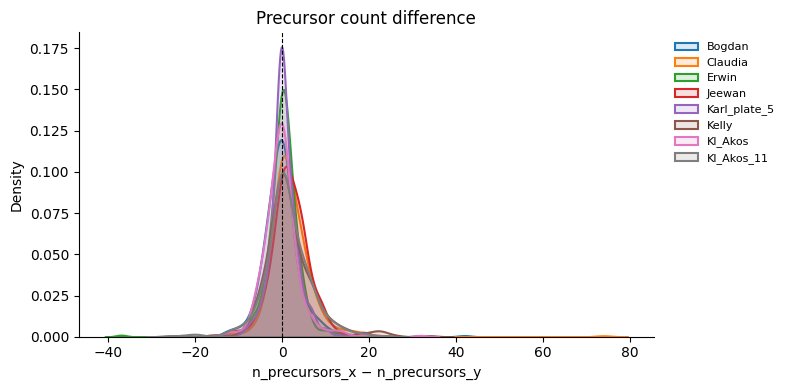

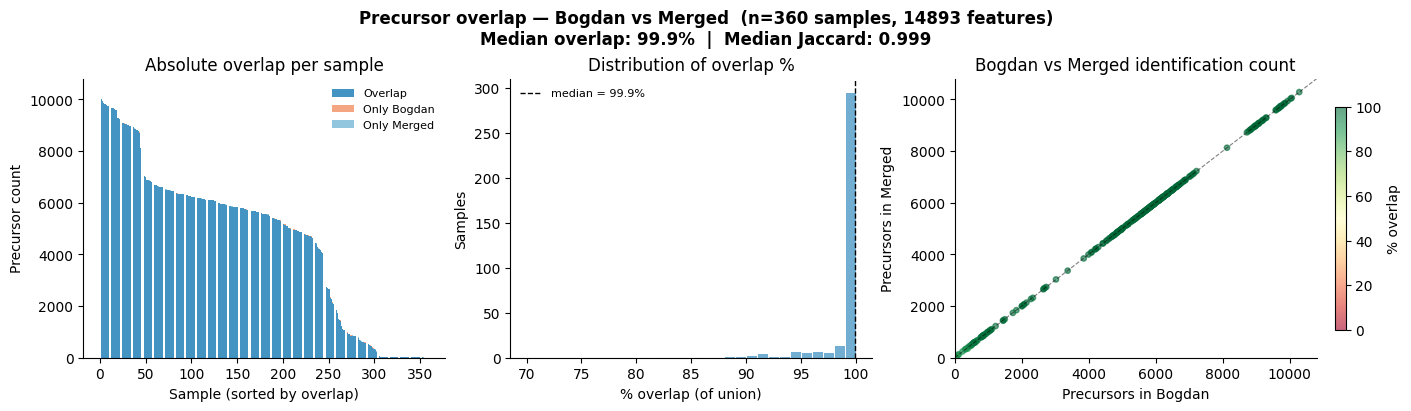

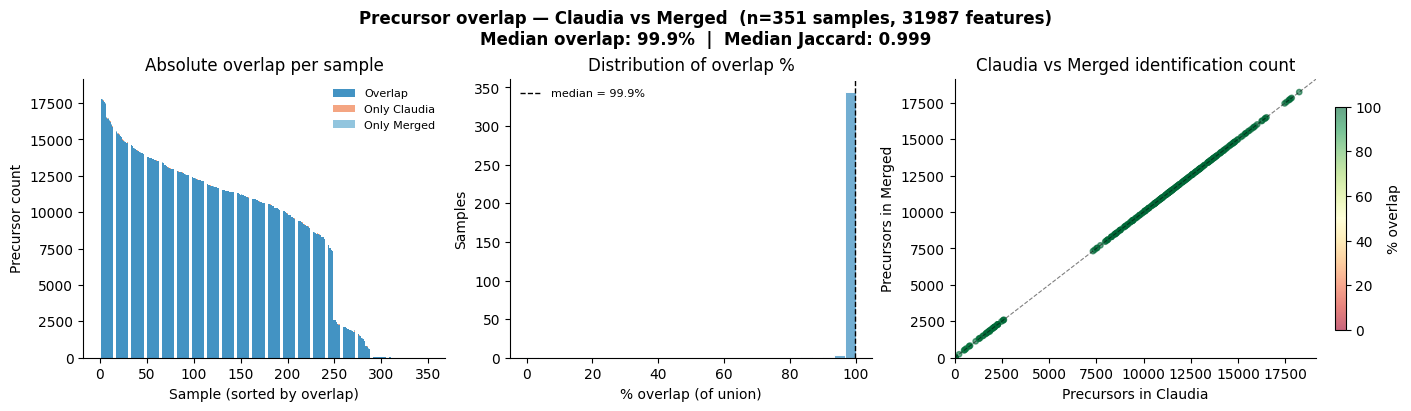

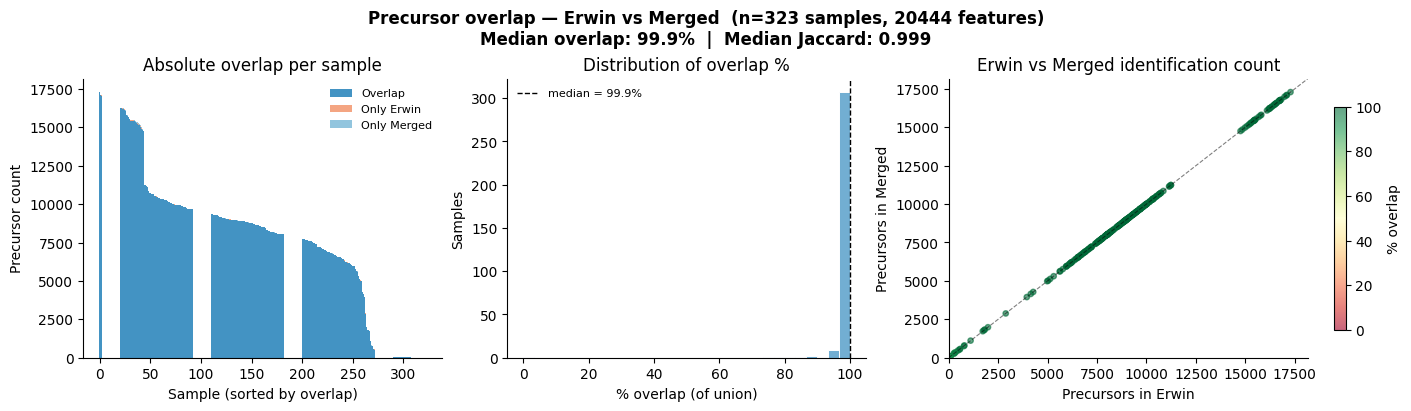

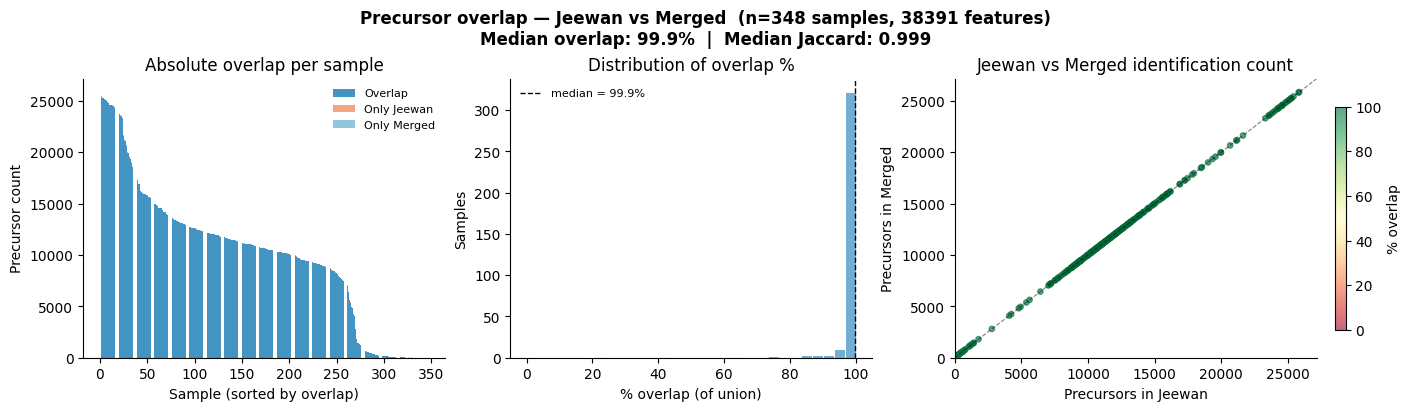

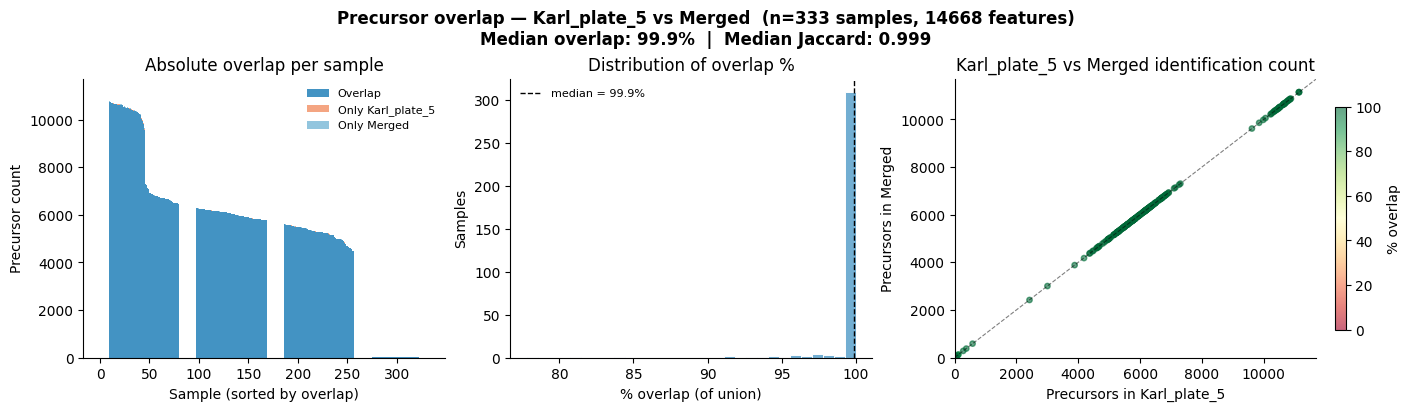

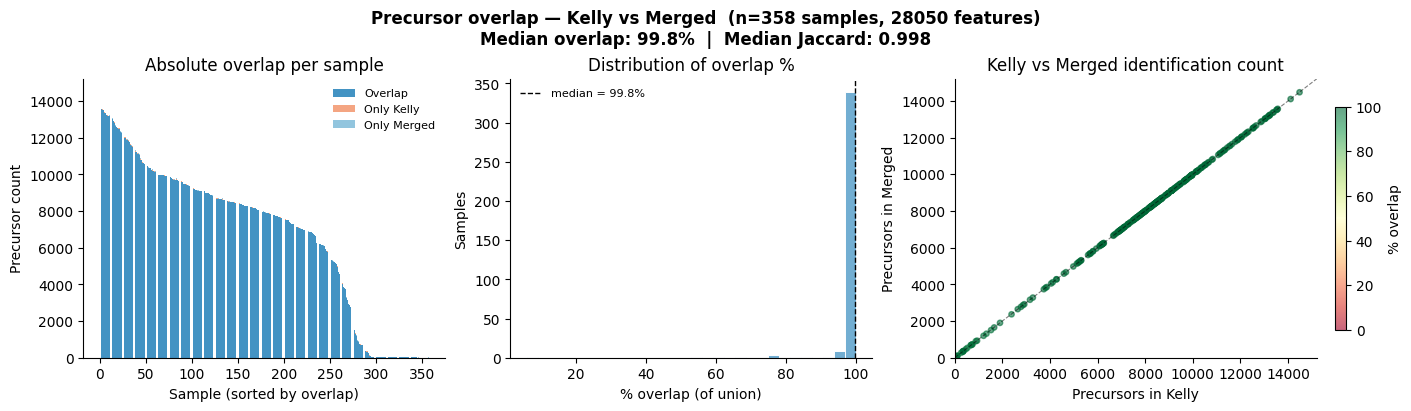

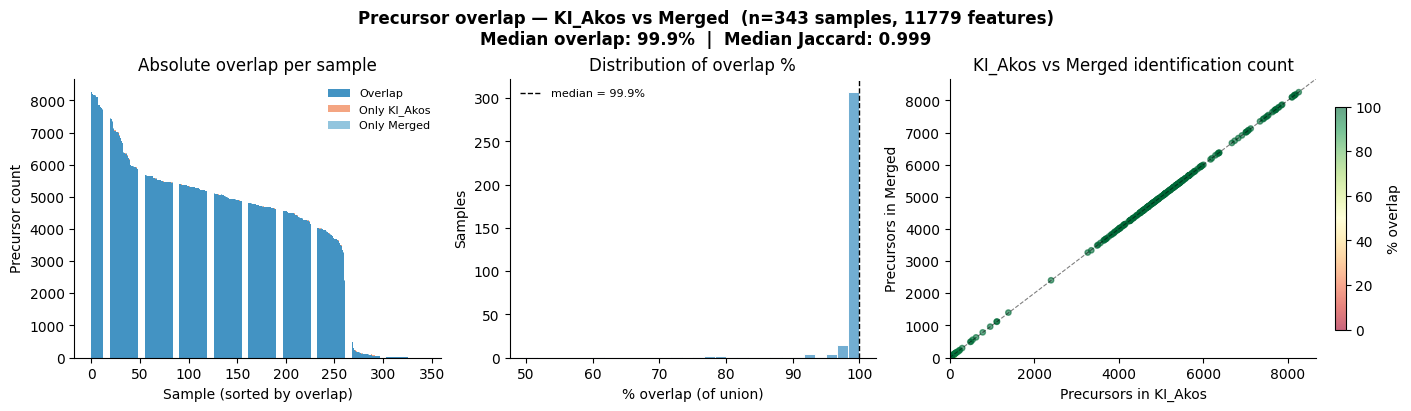

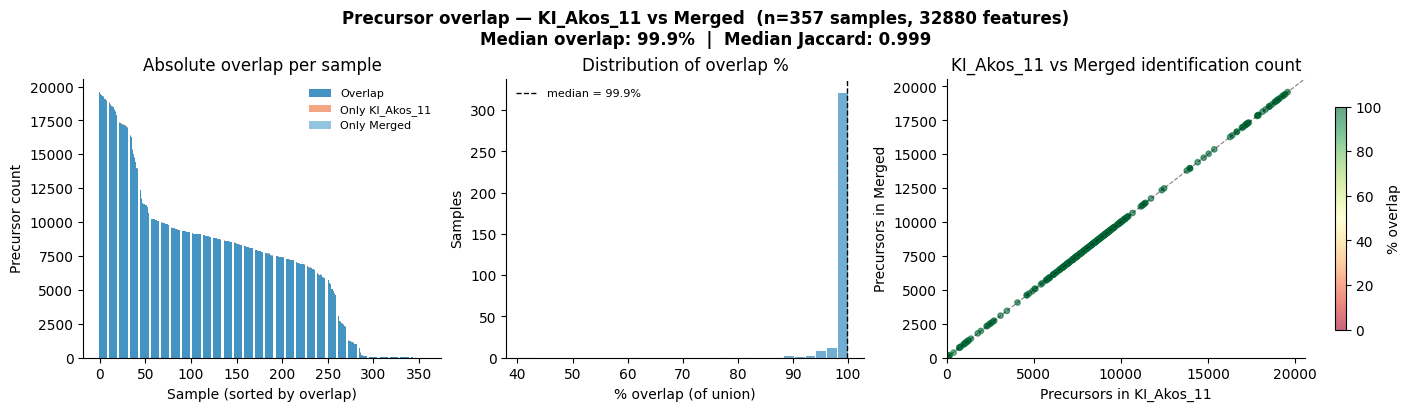

In [113]:
plot_precursor_count_diff(
    results  = comparisons,
    save_dir = False,
    show     = True,
)
for k, adata in adata_precursors.items():
    stats = plot_precursor_overlap(
        adata_a  = adata,
        adata_b  = adata_precursor_og,
        label_a  = k,
        label_b  = 'Merged',
        save_dir = False,
        show     = True,
    )


---